# Synthetic data sanity check

**All data on this page is synthetic** — generated by `backend/data/synthetic.py`, not
recorded from a real plant. See `backend/data/README.md` for exactly what's modeled vs.
invented, and `~/Desktop/PlantHealth-Decisions/02-real-data-search.md` for why no public
dataset could be used instead.

Goal of this notebook: confirm the four classes *look* physiologically plausible per the
brief — diurnal rhythm in all of them, heat = fast sharp spikes, drought = slow baseline
drift with shrinking diurnal amplitude and nothing fast, salinity = baseline shift with
moderate spiking (between drought and heat), plus visible 50 Hz hum / drift / movement
artefacts, plus the deliberately-injected incubator compressor confound on temperature.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "backend" / "data"))

import numpy as np
import matplotlib.pyplot as plt
from synthetic import generate_plant_recording, PlantRecordingConfig, HardwareConfig

CLASSES = ["healthy", "drought", "heat", "salinity"]
DURATION_DAYS = 4
FS_HZ = 10
SEED = 7

recordings = {}
for i, c in enumerate(CLASSES):
    cfg = PlantRecordingConfig(
        plant_id=f"{c}_sanitycheck", class_label=c,
        duration_days=DURATION_DAYS, seed=SEED + i,
        hardware=HardwareConfig(fs_hz=FS_HZ),
    )
    recordings[c] = generate_plant_recording(cfg)
    print(c, recordings[c].shape, "is_synthetic:", recordings[c]['is_synthetic'].iloc[0])

healthy (3456000, 9) is_synthetic: True


drought (3456000, 9) is_synthetic: True


heat (3456000, 9) is_synthetic: True


salinity (3456000, 9) is_synthetic: True


## 1. Full recording per class — diurnal rhythm + class signature

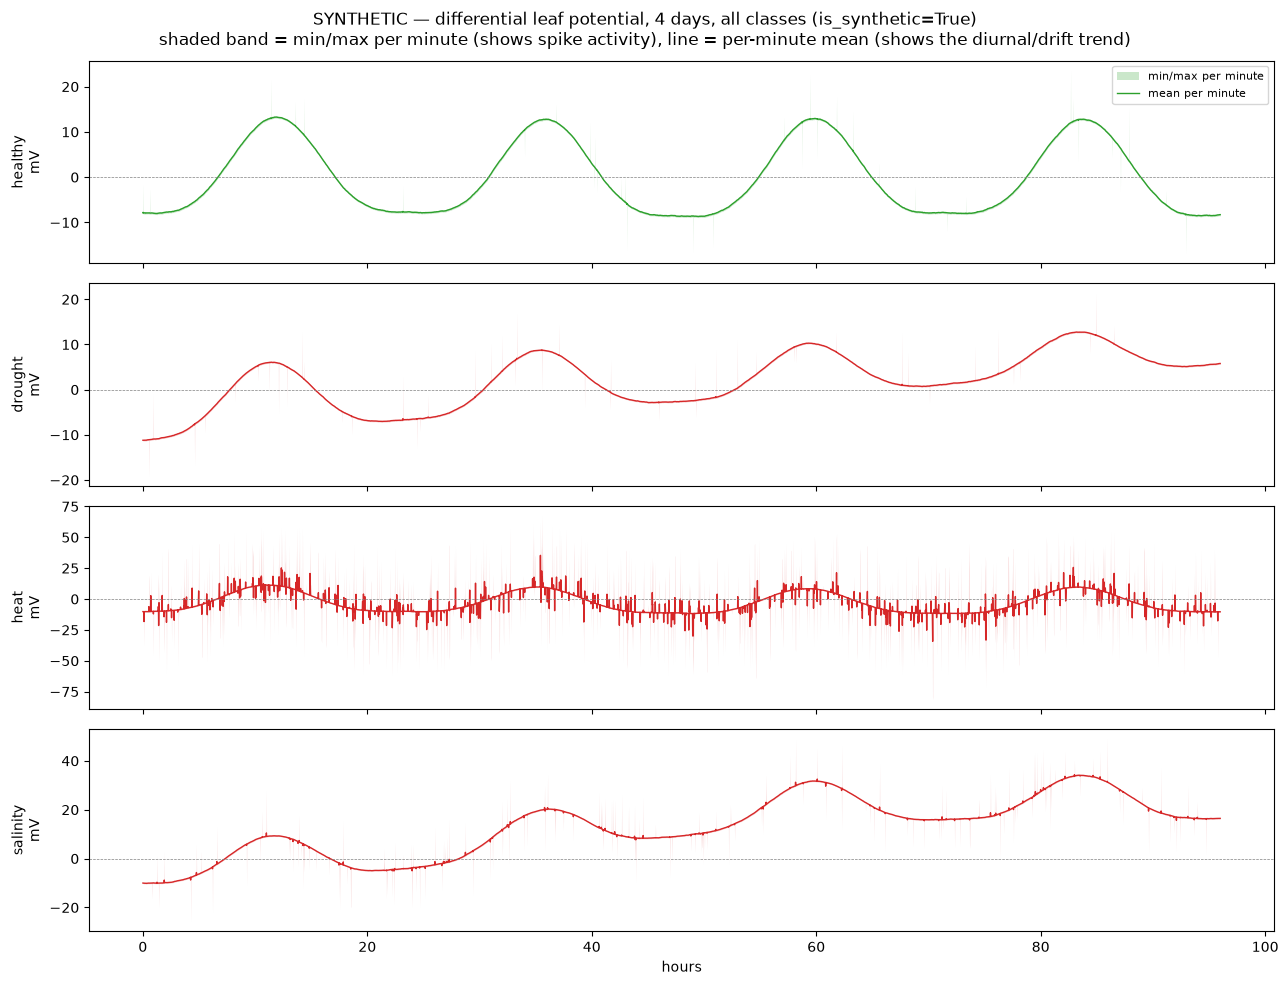

In [2]:
import pandas as pd

def envelope(df, bucket_s=60):
    """Min/max/mean per bucket — avoids the solid-noise-band look you get from
    plotting millions of raw samples at once; the zoomed cells below show the raw
    samples untouched."""
    bucket = (df['timestamp_s'] // bucket_s).astype(int)
    g = df.groupby(bucket)['potential_mv']
    return df['timestamp_s'].groupby(bucket).mean() / 3600, g.min(), g.max(), g.mean()

fig, axes = plt.subplots(4, 1, figsize=(13, 10), sharex=True)
for ax, c in zip(axes, CLASSES):
    t_h, lo, hi, mean = envelope(recordings[c])
    color = 'tab:green' if c == 'healthy' else 'tab:red'
    ax.fill_between(t_h, lo, hi, color=color, alpha=0.25, lw=0, label='min/max per minute')
    ax.plot(t_h, mean, color=color, lw=1, label='mean per minute')
    ax.set_ylabel(f"{c}\nmV")
    ax.axhline(0, color='gray', lw=0.5, ls='--')
axes[0].legend(loc='upper right', fontsize=8)
axes[-1].set_xlabel("hours")
fig.suptitle("SYNTHETIC — differential leaf potential, 4 days, all classes (is_synthetic=True)\n"
             "shaded band = min/max per minute (shows spike activity), line = per-minute mean (shows the diurnal/drift trend)")
plt.tight_layout()
plt.savefig("fig_01_full_recordings.png", dpi=110)
plt.show()

**What to check:** all four show the same ~24h diurnal swing. Drought's diurnal swing should
visibly shrink over the 4 days. Drought and salinity should show a clear baseline trend
(drought more linear, salinity more of a ramp-then-plateau). Heat should look mostly flat
at this zoomed-out scale *except* for occasional sharp spikes poking well outside the
diurnal band — zoom in below to see them properly.

## 2. Zoomed in — one hour, to see the fast structure

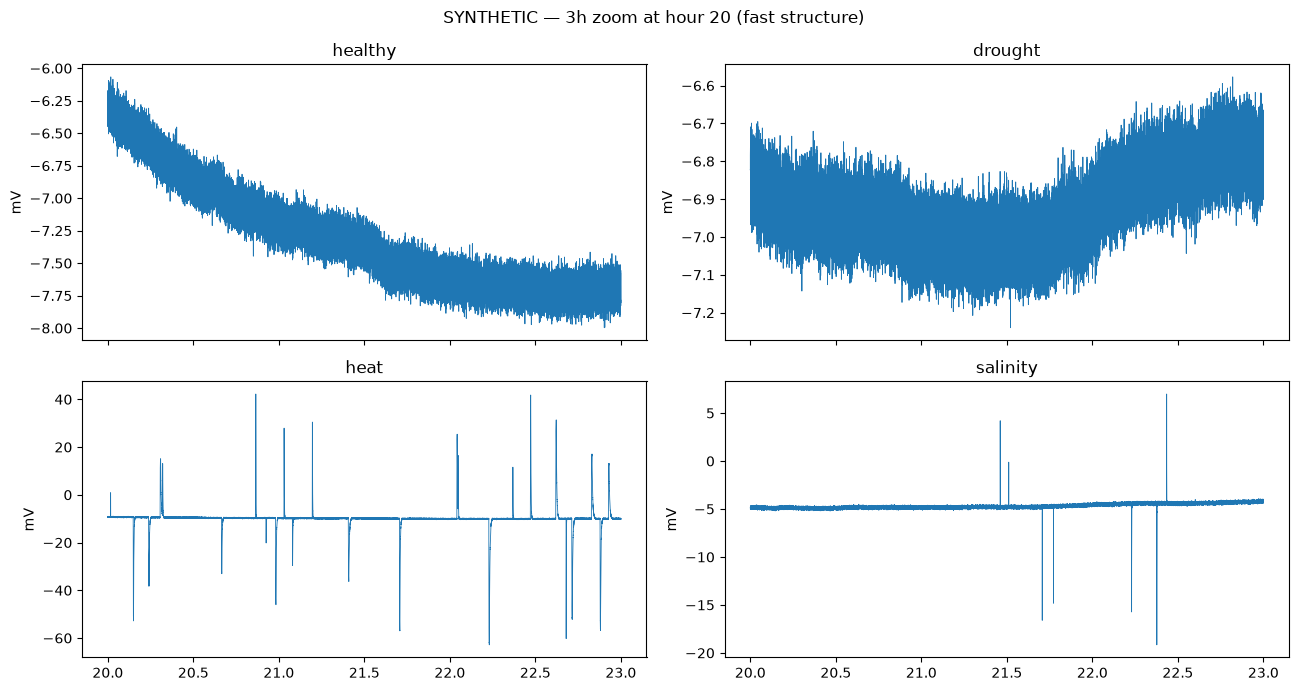

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True)
window_start_h, window_len_h = 20, 3
for ax, c in zip(axes.flat, CLASSES):
    df = recordings[c]
    t_hours = df['timestamp_s'] / 3600
    mask = (t_hours >= window_start_h) & (t_hours < window_start_h + window_len_h)
    ax.plot(t_hours[mask], df['potential_mv'][mask], lw=0.6)
    ax.set_title(c)
    ax.set_ylabel("mV")
fig.suptitle(f"SYNTHETIC — {window_len_h}h zoom at hour {window_start_h} (fast structure)")
plt.tight_layout()
plt.savefig("fig_02_zoom_fast_structure.png", dpi=110)
plt.show()

**What to check:** heat should show sharp tens-of-mV pulses rising and decaying over
seconds-to-minutes. Salinity should show *some* spiking, smaller/slower than heat. Drought
should look almost featureless at this zoom — "nothing fast happens". Healthy should look
like smooth drift + noise only.

## 3. Artefacts — 50 Hz hum and electrode drift are present in every class

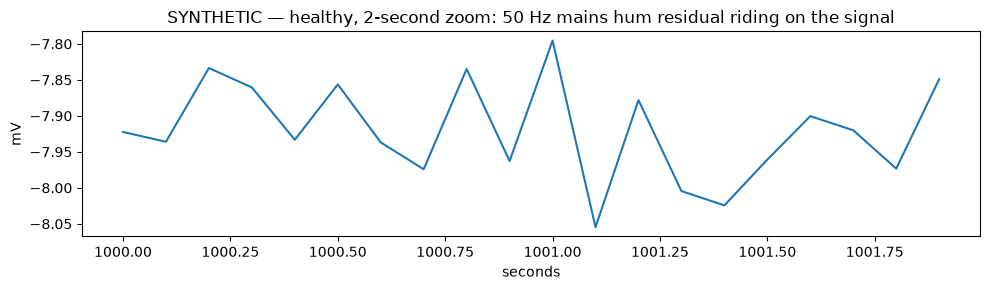

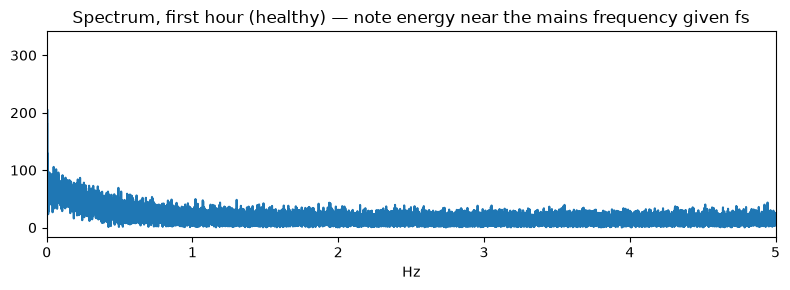

fs_hz = 10 => Nyquist = 5.0 Hz. At 10 Hz sampling the true 50 Hz hum aliases;
use --fs-hz >= 100 when generating a dataset meant for frequency-domain inspection of the hum itself.


In [4]:
df = recordings["healthy"]
t_s = df['timestamp_s'].values
mask = (t_s >= 1000) & (t_s < 1002)  # 2 seconds, enough to see 50 Hz cycles
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(t_s[mask], df['potential_mv'].values[mask])
ax.set_title("SYNTHETIC — healthy, 2-second zoom: 50 Hz mains hum residual riding on the signal")
ax.set_xlabel("seconds"); ax.set_ylabel("mV")
plt.tight_layout()
plt.savefig("fig_03_mains_hum_zoom.png", dpi=110)
plt.show()

# FFT to confirm the 50 Hz component is actually there
from numpy.fft import rfft, rfftfreq
window = df['potential_mv'].values[:FS_HZ * 3600]  # first hour
freqs = rfftfreq(len(window), d=1 / FS_HZ)
spectrum = np.abs(rfft(window - window.mean()))
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(freqs, spectrum)
ax.set_xlim(0, FS_HZ / 2)
ax.set_title("Spectrum, first hour (healthy) — note energy near the mains frequency given fs")
ax.set_xlabel("Hz")
plt.tight_layout()
plt.savefig("fig_03b_spectrum.png", dpi=110)
plt.show()
print("fs_hz =", FS_HZ, "=> Nyquist =", FS_HZ/2, "Hz. At 10 Hz sampling the true 50 Hz hum aliases;")
print("use --fs-hz >= 100 when generating a dataset meant for frequency-domain inspection of the hum itself.")

## 4. The compressor confound — heat's temperature channel, not the plant

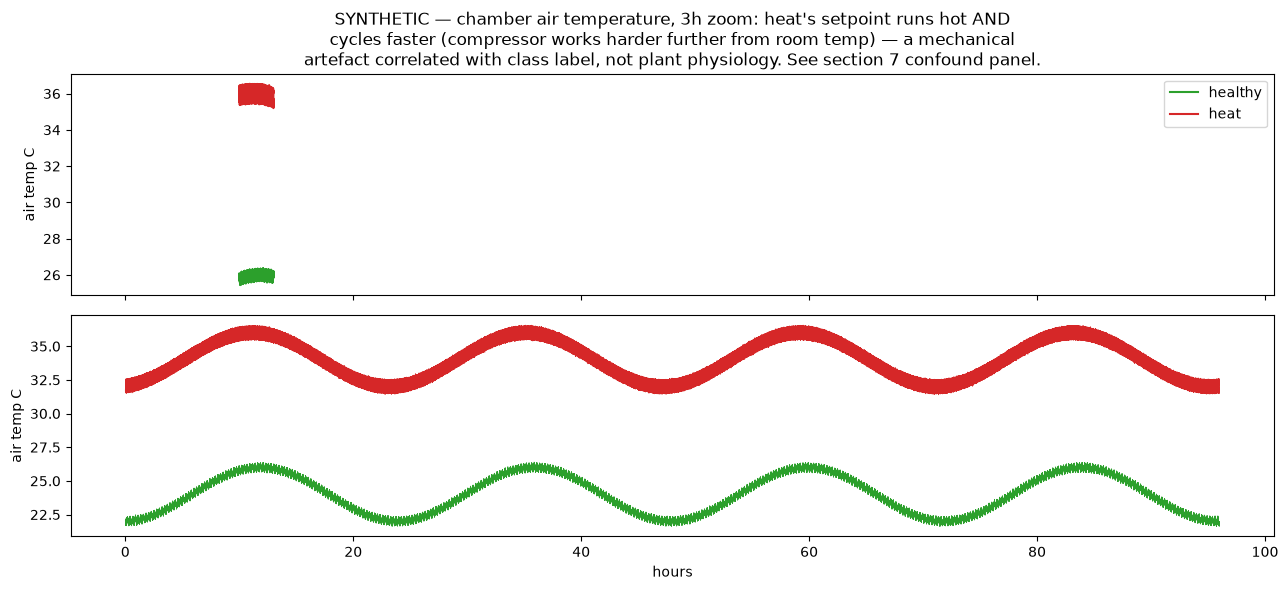

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
for c, color in [("healthy", "tab:green"), ("heat", "tab:red")]:
    df = recordings[c]
    t_hours = df['timestamp_s'] / 3600
    mask = (t_hours >= 10) & (t_hours < 13)
    axes[0].plot(t_hours[mask], df['air_temp_c'][mask], label=c, color=color)
axes[0].legend(); axes[0].set_ylabel("air temp C")
axes[0].set_title("SYNTHETIC — chamber air temperature, 3h zoom: heat's setpoint runs hot AND\n"
                   "cycles faster (compressor works harder further from room temp) — a mechanical\n"
                   "artefact correlated with class label, not plant physiology. See section 7 confound panel.")

for c, color in [("healthy", "tab:green"), ("heat", "tab:red")]:
    df = recordings[c]
    t_hours = df['timestamp_s'] / 3600
    axes[1].plot(t_hours, df['air_temp_c'], label=c, color=color, lw=0.5)
axes[1].set_xlabel("hours"); axes[1].set_ylabel("air temp C")
plt.tight_layout()
plt.savefig("fig_04_compressor_confound.png", dpi=110)
plt.show()

## Conclusion

If the plots above show: a shared diurnal rhythm, heat's sharp fast spikes, drought's slow
featureless drift with shrinking diurnal amplitude, salinity's intermediate spiking plus
baseline ramp, and a faster/stronger temperature ripple specifically on the heat class —
the generator matches the physiology brief and feature extraction (section 3) can proceed.

**Next step:** `backend/ml/features.py` + `backend/ml/train.py` — sliding-window features,
XGBoost, and the honest leave-one-plant-out vs. inflated-random-split comparison.